# Caso real 1: rizosfera contra filosfera en agaves y cactus

## De que va esta libreta

En las libretas 09 y 10 aprendimos la cadena composicional con datos **inventados**, donde
sabiamos la respuesta. Ahora toca lo de verdad: datos reales, sin respuesta conocida.

La pregunta es sencilla: **¿las bacterias que viven pegadas a la raiz (rizosfera) son
distintas de las que viven sobre las hojas (filosfera)?** Lo vamos a ver en agaves y
cactus de Guanajuato y Jalisco, muestreados por grupos de investigacion mexicanos.

Ninguna de estas muestras esta en el subset del taller: lo comprobamos en el camino.

## Como seguirla

Igual que la 09 y la 10: celdas cortas, una idea por celda, explicacion antes de cada
paso. La unica diferencia es que las funciones de apoyo y de figuras estan **aqui
mismo**, en la seccion 1, en vez de en un archivo aparte. No hace falta leerlas.

Necesita que exista `data/processed/`, que genera la libreta 01.

## Curso de Invierno — Microbioma de la rizósfera
### Instructor: Rafael Pérez-Estrada

⏱ **Duración estimada: ~30 min** (parte 3 de 3 del capítulo *Transformación composicional*)

**Cómo usar este notebook:** todas las celdas ya vienen escritas: ejecútalas en orden, siguiendo al instructor. Empieza por la celda **🔧 Setup**, que prepara el entorno igual en Google Colab y en tu computadora.  
Si te atrasas, ejecuta todas las celdas hasta donde vamos (en Colab: *Entorno de ejecución → Ejecutar anteriores*).

---

## 🔧 Setup y carga de datos (~5 min)

Prepara el código de apoyo del capítulo y descarga las tablas de MicroAgroBiome que usa este caso real (`datos/composicional.zip`), junto con la lista de muestras del proyecto (`datos/subset_proyecto.zip`). Con esto, la sección de preparación de abajo encuentra todo lo que necesita.

In [1]:
# Detección de entorno (VSCode local vs Google Colab) y preparación del código de apoyo
import os, sys, shutil, zipfile, urllib.request
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
LESSON = 'composicional'
NECESITA_DATOS = True    # el caso real descarga las tablas de MicroAgroBiome

# Archivos del repositorio (rama main)
RAMA = 'main'
REPO_URL = f'https://github.com/MicroAgroBiome/Curso_Invierno_2026/raw/{RAMA}/'
MODULOS = ['__init__', 'compositional', 'course_plots', 'simulation', 'batch']

if IN_COLAB:
    BASE = Path('/content')
else:
    # Local: sube hasta encontrar la carpeta datos/ (repo clonado); si no existe, usa la carpeta actual
    BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos').is_dir()), Path.cwd())

DATA_PATH = BASE / 'datos'
MODULE_PATH = BASE / 'src' / 'microagro_coda'
RESULTS_PATH = BASE / 'resultados' / LESSON

# Código de apoyo: en el repo ya está en src/; en Colab (o con el notebook suelto) se descarga
if not (MODULE_PATH / 'compositional.py').exists():
    MODULE_PATH.mkdir(parents=True, exist_ok=True)
    print("Descargando el código de apoyo...")
    for modulo in MODULOS:
        urllib.request.urlretrieve(f'{REPO_URL}src/microagro_coda/{modulo}.py', MODULE_PATH / f'{modulo}.py')
sys.path.insert(0, str(BASE / 'src'))

# Carpeta de trabajo: aquí quedan los resultados y, si hacen falta, los datos
PROCESSED_PATH = RESULTS_PATH / 'data' / 'processed'
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)


def traer(nombre):
    """Ruta local de datos/<nombre>: usa la del repo o la descarga."""
    ruta = DATA_PATH / nombre
    if not ruta.exists():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        print(f"Descargando {nombre}...")
        urllib.request.urlretrieve(f'{REPO_URL}datos/{nombre}', ruta)
    return ruta


if NECESITA_DATOS:
    if not (PROCESSED_PATH / 'genus-counts-matrix.csv').exists():
        with zipfile.ZipFile(traer('composicional.zip')) as zf:
            for miembro in zf.namelist():
                if not miembro.endswith('/'):
                    (PROCESSED_PATH / Path(miembro).name).write_bytes(zf.read(miembro))
    shutil.copy(traer('subset_proyecto.zip'), RESULTS_PATH / 'data' / 'subset_proyecto.zip')

# El resto del notebook trabaja desde la carpeta de resultados
os.chdir(RESULTS_PATH)

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local (VSCode)'}")
print(f"Carpeta de trabajo: {os.path.relpath(RESULTS_PATH, BASE)}")

Entorno: Local (VSCode)
Carpeta de trabajo: resultados\composicional


## 1. Preparacion

Primero decimos donde esta el codigo del proyecto.

In [2]:
from pathlib import Path
import sys

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

Ahora las herramientas. `comp` y `batch` son modulos del proyecto que ya usamos antes.

In [3]:
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from microagro_coda import batch
from microagro_coda import compositional as comp
from microagro_coda import course_plots as figuras

figuras.preparar_libreta()

In [4]:
UMBRAL_DE_PREVALENCIA = 0.70   # el mismo de las libretas 09 y 10
SEMILLA = 42

### Funciones de apoyo

Estas dos celdas solo **definen** funciones: para leer las tablas, para revisar duplicados,
para quedarnos con las bacterias y para dibujar. No hace falta leerlas para seguir la
libreta; basta con ejecutarlas.

In [5]:
CARPETA_PROCESADOS = RAIZ / "data" / "processed"


def cargar_tablas():
    """Lee las cuatro tablas que deja la libreta 01 en data/processed."""
    conteos = pd.read_csv(CARPETA_PROCESADOS / "genus-counts-matrix.csv", index_col=0)
    metadatos = pd.read_csv(CARPETA_PROCESADOS / "sample-metadata.csv", index_col="sample")
    metadatos["doi"] = metadatos["doi"].str.strip()
    calidad = pd.read_csv(CARPETA_PROCESADOS / "sample-qc.csv", index_col="sample")
    linaje = pd.read_csv(CARPETA_PROCESADOS / "genus-lineage-map.csv", index_col="genus")
    return conteos, metadatos, calidad, linaje


def muestras_del_taller():
    """IDs de las muestras del subset de los estudiantes, leidos dentro del zip sin extraerlo."""
    for carpeta in [RAIZ.parent / "data", RAIZ / "data"]:
        ruta = carpeta / "subset_proyecto.zip"
        if ruta.exists():
            with zipfile.ZipFile(ruta) as archivo:
                with archivo.open("subset_proyecto/taller_samples.csv") as tabla:
                    return set(pd.read_csv(tabla)["sample_id"])
    raise FileNotFoundError("No encuentro subset_proyecto.zip en ../data ni en data/")


def perfiles_duplicados(conteos):
    """Muestras cuyo perfil de conteos es identico, numero por numero, al de otra muestra.

    Devuelve una tabla con una fila por muestra repetida y una columna `grupo` que junta
    a las que son copia una de otra. Si no hay ninguna, la tabla sale vacia.
    """
    repetidas = conteos[conteos.duplicated(keep=False)]
    if repetidas.empty:
        return pd.DataFrame(columns=["grupo"])
    huella = repetidas.apply(lambda fila: hash(fila.to_numpy().tobytes()), axis=1)
    grupo = huella.map({valor: numero + 1 for numero, valor in enumerate(huella.unique())})
    return pd.DataFrame({"grupo": grupo}).sort_values("grupo")


def solo_bacterias(conteos, linaje):
    """Se queda con las columnas (generos) cuyo reino es Bacteria."""
    reino = linaje["kingdom"].reindex(conteos.columns)
    return conteos.loc[:, reino == "Bacteria"]

In [6]:
COLORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]


def colores_por_grupo(etiquetas):
    """Asigna un color fijo a cada grupo, en orden alfabetico."""
    grupos = sorted(pd.Series(etiquetas).unique())
    return {grupo: COLORES[numero % len(COLORES)] for numero, grupo in enumerate(grupos)}


def figura_calidad(calidad, etiquetas):
    """Tres paneles por grupo: lecturas, fraccion sin clasificar y fraccion asignada a genero."""
    paneles = {
        "lecturas por muestra (log10)": np.log10(calidad["library_size"]),
        "fraccion sin clasificar": calidad["unclassified_fraction"],
        "fraccion asignada a genero": calidad["genus_mass"],
    }
    colores = colores_por_grupo(etiquetas)
    grupos = list(colores)
    generador = np.random.default_rng(0)

    figura, ejes = plt.subplots(1, 3, figsize=(13, 3.8))
    for eje, (titulo, valores) in zip(ejes, paneles.items()):
        datos = [valores[etiquetas == grupo].to_numpy() for grupo in grupos]
        eje.boxplot(datos, widths=0.5, showfliers=False)
        for posicion, (grupo, puntos) in enumerate(zip(grupos, datos), start=1):
            x = posicion + generador.uniform(-0.12, 0.12, len(puntos))
            eje.scatter(x, puntos, s=22, alpha=0.75, color=colores[grupo], zorder=3)
        eje.set_xticks(range(1, len(grupos) + 1))
        eje.set_xticklabels(grupos)
        eje.set_title(titulo)
    figura.tight_layout()
    return figura


def figura_acp(puntos_sin_clr, puntos_con_clr, etiquetas, varianza_sin_clr, varianza_con_clr):
    """PC1 frente a PC2 sin y con CLR, coloreado por grupo."""
    colores = colores_por_grupo(etiquetas)
    tamano = 45 if len(etiquetas) < 60 else 16
    figura, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
    datos = [("Sin CLR", puntos_sin_clr, varianza_sin_clr),
             ("Con CLR", puntos_con_clr, varianza_con_clr)]
    for eje, (titulo, puntos, varianza) in zip(ejes, datos):
        for grupo, color in colores.items():
            es_del_grupo = etiquetas == grupo
            eje.scatter(puntos.loc[es_del_grupo, "PC1"], puntos.loc[es_del_grupo, "PC2"],
                        s=tamano, alpha=0.8, color=color, label=grupo)
        eje.set_title(titulo)
        eje.set_xlabel(f"PC1 ({100 * varianza[0]:.1f} %)")
        eje.set_ylabel(f"PC2 ({100 * varianza[1]:.1f} %)")
    ejes[0].legend(fontsize=8)
    figura.suptitle("Las mismas muestras, antes y despues de la correccion", y=1.02)
    figura.tight_layout()
    return figura


def figura_generos(tabla, grupo_positivo, grupo_negativo, cuantos=10, eta2_minimo=0.5):
    """Barras de los generos que mas cambian entre dos grupos.

    `tabla` necesita las columnas `diferencia` (media CLR del grupo positivo menos la del
    negativo) y `eta2`. Solo se consideran los generos con eta2 >= eta2_minimo, es decir,
    los que cambian de forma consistente y no por una sola muestra.
    """
    consistentes = tabla[tabla["eta2"] >= eta2_minimo]
    elegidos = pd.concat([consistentes.nsmallest(cuantos, "diferencia"),
                          consistentes.nlargest(cuantos, "diferencia")]).sort_values("diferencia")
    colores = colores_por_grupo([grupo_positivo, grupo_negativo])
    barras = [colores[grupo_positivo] if valor > 0 else colores[grupo_negativo]
              for valor in elegidos["diferencia"]]

    figura, eje = plt.subplots(figsize=(8, 0.32 * len(elegidos) + 1.2))
    eje.barh(range(len(elegidos)), elegidos["diferencia"], color=barras)
    eje.set_yticks(range(len(elegidos)))
    eje.set_yticklabels(elegidos.index, fontsize=8, style="italic")
    eje.axvline(0, color="grey", linewidth=1)
    eje.set_xlabel(f"diferencia media de CLR ({grupo_positivo} menos {grupo_negativo})")
    parches = [plt.Rectangle((0, 0), 1, 1, color=colores[grupo_positivo]),
               plt.Rectangle((0, 0), 1, 1, color=colores[grupo_negativo])]
    eje.legend(parches, [f"mas en {grupo_positivo}", f"mas en {grupo_negativo}"],
               fontsize=8, loc="lower right")
    eje.set_title(f"Generos que mas cambian (eta2 >= {eta2_minimo})")
    figura.tight_layout()
    return figura


def calcular_acp(tabla):
    """Escala la tabla, calcula el ACP y devuelve los puntos y la varianza explicada."""
    escalada = StandardScaler().fit_transform(tabla)
    modelo = PCA(n_components=2, random_state=SEMILLA)
    puntos = modelo.fit_transform(escalada)
    puntos = pd.DataFrame(puntos, index=tabla.index, columns=["PC1", "PC2"])
    return puntos, modelo.explained_variance_ratio_

## 2. Los datos reales

Son cuatro tablas, todas generadas por la libreta 01 a partir del BIOM completo:

- `conteos`: lecturas por muestra (filas) y por genero (columnas), igual que en la 09.
- `metadatos`: de donde viene cada muestra (cultivo, parte de la planta, pais, estudio...).
- `calidad`: numeros tecnicos de cada muestra, como cuantas lecturas tiene.
- `linaje`: a que reino, filo, clase... pertenece cada genero.

In [7]:
conteos, metadatos, calidad, linaje = cargar_tablas()

In [8]:
conteos.shape

(550, 4611)

550 muestras y mas de 4,600 generos. Veamos las columnas de `metadatos` que nos interesan.

In [9]:
metadatos[["host_name", "plant_part", "state", "country", "doi"]].head()

,host_name,plant_part,state,country,doi
sample,,,,,
SRR10127267,Blue agave,Phyllosphere,Jalisco,Mexico,NaN
SRR10127271,Bilberry cactus,Phyllosphere,Guanajuato,Mexico,NaN
SRR10418054,Sunflower,Rhizosphere,Bloemhof,South Africa,10.3390/agriculture11020167
SRR10418081,Sunflower,Rhizosphere,Bloemhof,South Africa,10.3390/agriculture11020167
SRR10426233,Sunflower,Rhizosphere,Palmietfontein,South Africa,10.3390/agriculture11020167


### Elegir las muestras

Nos quedamos con los cuatro agaves y cactus del conjunto y con dos partes de la planta:

- **Rhizosphere** (rizosfera): el suelo pegado a la raiz.
- **Phyllosphere** (filosfera): la superficie de las hojas (en agaves y cactus, las pencas
  y cladodios).

In [10]:
HOSPEDEROS = ["Pulque agave", "Blue agave", "Bilberry cactus", "Wheel cactus"]
COMPARTIMENTOS = ["Rhizosphere", "Phyllosphere"]

es_agave_o_cactus = metadatos["host_name"].isin(HOSPEDEROS)
es_raiz_u_hoja = metadatos["plant_part"].isin(COMPARTIMENTOS)

elegidas = metadatos[es_agave_o_cactus & es_raiz_u_hoja]
len(elegidas)

15

Comprobamos que **ninguna** de estas muestras esta en el subset del taller.

In [11]:
#| label: l3-taller
del_taller = muestras_del_taller()
en_comun = set(elegidas.index) & del_taller

assert len(en_comun) == 0, "hay muestras del taller en el caso real"
print("muestras del taller:", len(del_taller), "| en comun con este caso:", len(en_comun))

muestras del taller: 41 | en comun con este caso: 0


¿Cuantas hay de cada planta en cada compartimento?

In [12]:
#| label: tbl-l3-diseno
#| tbl-cap: "Muestras por hospedero y compartimento."
pd.crosstab(elegidas["host_name"], elegidas["plant_part"])

plant_part,Phyllosphere,Rhizosphere
host_name,,
Bilberry cactus,2,2
Blue agave,1,2
Pulque agave,2,2
Wheel cactus,2,2


Casi todas las plantas tienen muestras de raiz **y** de hoja. Eso es bueno: si comparamos
compartimentos, no estamos comparando sin querer una planta contra otra.

¿Y de que estudio sale cada una?

In [13]:
#| label: tbl-l3-estudios
#| tbl-cap: "Muestras por estudio de origen y compartimento."
pd.crosstab(elegidas["doi"].fillna("sin dato"), elegidas["plant_part"])

plant_part,Phyllosphere,Rhizosphere
doi,,
10.1016/j.isci.2020.101624,4,3
10.3389/fmicb.2020.542742,1,5
sin dato,2,0


Tres fuentes: dos articulos y dos muestras sin DOI en los metadatos. Fijate en que el
reparto no es parejo: un estudio aporta sobre todo raices y otro sobre todo hojas.
Volveremos sobre esto en la seccion 6.

Nuestra etiqueta es el compartimento.

In [14]:
etiquetas = elegidas["plant_part"]
etiquetas.value_counts()

Rhizosphere     8
Phyllosphere    7
Name: plant_part, dtype: int64

## 3. Revisiones antes de analizar

Con datos reales, **antes** de cualquier ACP conviene hacer tres revisiones. Esta es la
lista que se van a llevar a su subset:

1. ¿Hay muestras repetidas?
2. ¿Los grupos se secuenciaron de forma parecida?
3. ¿Que hay realmente en la tabla?

### Revision 1: ¿hay muestras repetidas?

En las bases de datos publicas a veces la **misma** secuenciacion aparece varias veces,
con distinto identificador o subida por distintos articulos. Si no lo notamos:

- contamos la misma muestra dos veces y creemos tener mas datos de los que hay,
- y en la validacion cruzada la copia puede quedar en entrenamiento y el original en
  prueba: el modelo "acierta" porque ya la habia visto.

La forma mas directa de detectarlo: buscar filas de conteos **identicas numero por
numero**.

In [15]:
#| label: l3-duplicados
conteos_elegidos = conteos.loc[elegidas.index]

repetidas = perfiles_duplicados(conteos_elegidos)
print("muestras con un perfil identico al de otra:", len(repetidas))

muestras con un perfil identico al de otra: 0


Aqui no hay ninguna. **Guarden esta celda**: es de las revisiones que nadie hace y que
luego cambian los resultados.

### Revision 2: ¿los grupos se secuenciaron de forma parecida?

Tres numeros tecnicos por muestra:

- **lecturas por muestra**: la profundidad, como en la 09.
- **fraccion sin clasificar**: lecturas que Kraken2 no pudo asignar a ningun organismo.
- **fraccion asignada a genero**: lecturas que si llegaron hasta genero, que son las que
  usamos.

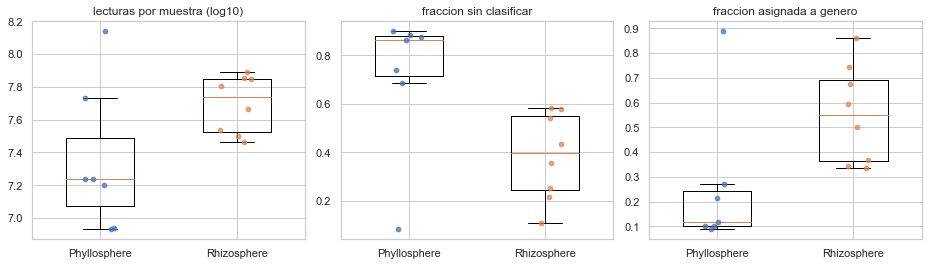

In [16]:
#| label: fig-l3-calidad
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Calidad técnica por compartimento: lecturas por muestra, fracción sin clasificar y fracción asignada a género."
figura = figura_calidad(calidad.loc[elegidas.index], etiquetas)

In [17]:
#| label: tbl-l3-calidad
#| tbl-cap: "Mediana de los indicadores técnicos por compartimento."
columnas_tecnicas = ["library_size", "unclassified_fraction", "genus_mass"]
calidad.loc[elegidas.index, columnas_tecnicas].groupby(etiquetas).median().round(2)

,library_size,unclassified_fraction,genus_mass
plant_part,,,
Phyllosphere,17278308.0,0.86,0.12
Rhizosphere,55035493.5,0.40,0.55


La diferencia es enorme: en la filosfera la mayoria de las lecturas **no se clasifican**.
Tiene explicacion biologica: sobre una hoja hay muy pocas bacterias, asi que casi todo el
ADN extraido es de la propia planta, y Kraken2 no la reconoce. En la rizosfera hay mucha
mas biomasa microbiana.

Hay una excepcion: una hoja de agave azul (`SRR10127267`, de las que no tienen DOI) se
parece mas a una raiz que a una hoja en estos numeros. Ojo con ella en el ACP.

> Que los grupos difieran en calidad no invalida el analisis, pero hay que tenerlo
> presente: algunas diferencias que encontremos pueden ser tecnicas y no biologicas.

### Revision 3: ¿que hay en la tabla?

In [18]:
#| label: l3-reinos
linaje.loc[conteos.columns, "kingdom"].value_counts()

Viruses      2464
Bacteria     1992
Archaea       148
Eukaryota       7
Name: kingdom, dtype: int64

Mas de la mitad de las columnas son **virus**. Nuestra pregunta es sobre bacterias, y la
asignacion de virus con Kraken2 es menos fiable, asi que nos quedamos solo con bacterias.

In [19]:
bacterias = solo_bacterias(conteos_elegidos, linaje)
bacterias.shape

(15, 1992)

## 4. La cadena composicional

Los mismos cuatro pasos de la libreta 09 (amalgamar, recerrar, sustituir ceros y CLR),
en una sola llamada, como en la 10.

In [20]:
relativa = bacterias.div(bacterias.sum(axis=1), axis=0)
cadena = comp.compositional_chain(relativa, min_prevalence=UMBRAL_DE_PREVALENCIA)

sin_clr = cadena["amalgamated"]   # abundancia relativa, sin corregir
con_clr = cadena["clr"]           # la misma tabla tras el CLR

In [21]:
sin_clr.shape, con_clr.shape

((15, 1975), (15, 1975))

Casi no se pierden generos al amalgamar. Es lo esperable en metagenomas tan profundos
(decenas de millones de lecturas): casi todos los generos reciben alguna lectura en casi
todas las muestras.

In [22]:
(bacterias == 0).to_numpy().mean()

0.009136546184738956

Menos del 1 % de ceros, frente al 36 % de los datos simulados.

## 5. Primera mirada: el ACP

Igual que en la 10: escalamos, calculamos el ACP con las dos tablas y comparamos.
**El ACP no ve las etiquetas.**

In [23]:
puntos_sin_clr, varianza_sin_clr = calcular_acp(sin_clr)
puntos_con_clr, varianza_con_clr = calcular_acp(con_clr)

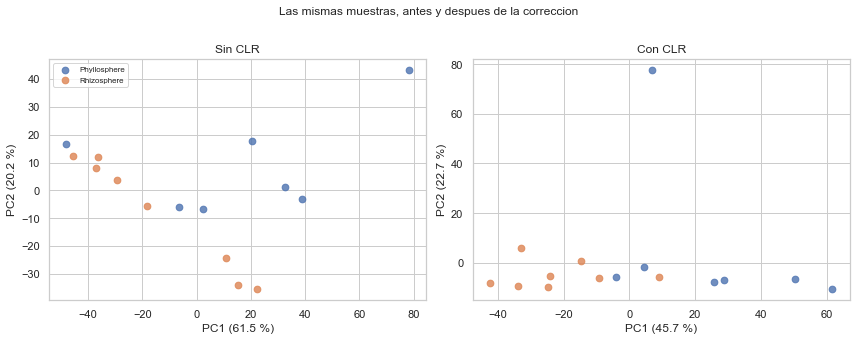

In [24]:
#| label: fig-l3-acp-real
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "ACP de rizosfera y filosfera de agaves y cactus, sin CLR (izquierda) y con CLR (derecha)."
figura = figura_acp(puntos_sin_clr, puntos_con_clr, etiquetas,
                    varianza_sin_clr, varianza_con_clr)

**Sin CLR** las hojas y las raices se mezclan: hay raices a los dos lados del eje
horizontal y hojas en medio de ellas.

**Con CLR** el eje horizontal (PC1) ordena las muestras de raiz a hoja: las raices quedan
a la izquierda y las hojas a la derecha, con un par de muestras en la zona de en medio. Es
lo mismo que vimos con los datos simulados de la 10, ahora con datos reales.

El punto solitario de arriba es la hoja de agave azul que ya habia salido rara en la
revision 2 (`SRR10127267`). El segundo eje esta dedicado casi entero a ella.

Para no quedarnos en "a ojo", medimos que fraccion de la variacion de cada eje explica el
compartimento. Es el $\eta^2$: 0 si el eje no tiene nada que ver con el grupo, 1 si el eje
*es* el grupo.

In [25]:
#| label: tbl-l3-eta2
#| tbl-cap: "Fracción de la variación de cada eje del ACP que explica el compartimento (η²)."
separacion = pd.DataFrame({
    "sin CLR": batch.eta_squared_by_feature(puntos_sin_clr, etiquetas),
    "con CLR": batch.eta_squared_by_feature(puntos_con_clr, etiquetas),
})
separacion.round(2)

,sin CLR,con CLR
PC1,0.20,0.60
PC2,0.18,0.06


El compartimento explica el 20 % de PC1 sin CLR y el **60 %** con CLR. Mismas muestras,
mismos generos: solo cambio la representacion.

## 6. ¿Es real la diferencia?

El ACP sugiere, pero no prueba. Para eso usamos una **PERMANOVA**:

1. Calculamos la distancia entre cada par de muestras. Sobre la tabla CLR, la distancia
   normal es la **distancia de Aitchison**, la correcta para composiciones.
2. Medimos que parte de esas distancias se explica por el grupo: es el **$R^2$**.
3. Barajamos las etiquetas 999 veces y vemos cuantas veces el azar da un resultado igual
   o mejor: es el **valor p**.

In [26]:
#| label: l3-permanova
resultado = batch.distance_r2(con_clr, etiquetas, n_permutations=999, random_state=SEMILLA)
resultado

{'r2': 0.3057643204559082,
 'pseudo_f': 5.725629325961996,
 'p_value': 0.001,
 'n_groups': 2,
 'n_permutations': 999}

- **R² = 0.31**: el compartimento explica cerca de un tercio de las diferencias entre
  muestras.
- **p = 0.001**: ninguna de las 999 barajadas dio un resultado tan bueno. Es el valor
  mas pequeno posible con 999 permutaciones.

Pero el compartimento no es lo unico que cambia entre muestras. Repetimos la cuenta con la
planta y con el estudio para ponerlo en contexto.

In [27]:
#| label: tbl-l3-factores
#| tbl-cap: "PERMANOVA sobre la distancia de Aitchison para tres factores."
factores = {
    "compartimento": etiquetas,
    "planta": elegidas["host_name"],
    "estudio": elegidas["doi"].fillna("sin dato"),
}

filas = []
for nombre, grupos in factores.items():
    r = batch.distance_r2(con_clr, grupos, n_permutations=999, random_state=SEMILLA)
    filas.append({"factor": nombre, "R2": round(r["r2"], 3), "p": r["p_value"]})

pd.DataFrame(filas)

,factor,R2,p
0,compartimento,0.306,0.001
1,planta,0.325,0.048
2,estudio,0.239,0.061


La planta tiene un R² parecido (0.33), pero un valor p mucho peor (0.048). ¿Por que, si
explica lo mismo?

Porque **con mas grupos, el R² sube solo por azar**. La planta tiene 4 grupos y el
compartimento 2: repartir 15 muestras en 4 cajas siempre "explica" algo, aunque las
etiquetas no tengan sentido. Por eso, para comparar factores con distinto numero de grupos,
hay que mirar el valor p y no solo el R².

El estudio no llega a ser significativo (p = 0.061). Aun asi, como el reparto por estudio
no era parejo, hagamos una prueba mas: repetir la PERMANOVA **dentro de un solo
estudio**, el que tiene hojas y raices.

In [28]:
#| label: l3-permanova-estudio
del_mismo_estudio = elegidas["doi"] == "10.1016/j.isci.2020.101624"

batch.distance_r2(con_clr[del_mismo_estudio], etiquetas[del_mismo_estudio],
                  n_permutations=999, random_state=SEMILLA)

{'r2': 0.3509796095041383,
 'pseudo_f': 2.703918202292415,
 'p_value': 0.054,
 'n_groups': 2,
 'n_permutations': 999}

Dentro de un solo estudio el compartimento explica lo mismo o un poco mas (R² = 0.35). La
diferencia entre raiz y hoja no la fabrico mezclar laboratorios.

El valor p (0.054) no baja de 0.05 por una razon de aritmetica: con 7 muestras solo hay
35 formas de repartirlas en 4 hojas y 3 raices, asi que el p mas pequeno posible es
1/35 ≈ 0.03. Con tan pocas muestras, el R² dice mas que el p.

### ¿Depende el resultado de mis decisiones?

Elegimos un umbral de prevalencia de 70 %. Si la conclusion cambiara por completo con otro
umbral, no seria muy solida. Probemos varios.

In [29]:
#| label: tbl-l3-umbral
#| tbl-cap: "Sensibilidad de la PERMANOVA al umbral de prevalencia usado al amalgamar."
filas = []
for umbral in [0.30, 0.50, 0.70, 0.90]:
    clr_umbral = comp.compositional_chain(relativa, min_prevalence=umbral)["clr"]
    r = batch.distance_r2(clr_umbral, etiquetas, n_permutations=999, random_state=SEMILLA)
    filas.append({"umbral": umbral, "generos": clr_umbral.shape[1],
                  "R2": round(r["r2"], 3), "p": r["p_value"]})

pd.DataFrame(filas)

,umbral,generos,R2,p
0,0.3,1982,0.151,0.001
1,0.5,1978,0.171,0.001
2,0.7,1975,0.306,0.001
3,0.9,1969,0.306,0.001


El **tamano** del efecto cambia (R² entre 0.15 y 0.31) pero la **conclusion** no: en todos
los casos p = 0.001.

¿Por que se mueve el R²? Al cambiar el umbral cambia cuantos ceros quedan por sustituir. Y
un cero sustituido vale un numero diminuto, cuyo logaritmo es un numero negativo enorme:
unos pocos ceros pesan mucho en las distancias. Es una buena razon para no amalgamar
demasiado poco.

Una ultima prueba de este tipo: ¿y si quitamos la hoja rara de agave azul?

In [30]:
#| label: l3-sin-rara
sin_la_rara = elegidas.index != "SRR10127267"

batch.distance_r2(con_clr[sin_la_rara], etiquetas[sin_la_rara],
                  n_permutations=999, random_state=SEMILLA)

{'r2': 0.41080020854345844,
 'pseudo_f': 8.36660598663009,
 'p_value': 0.001,
 'n_groups': 2,
 'n_permutations': 999}

Sin ella el efecto es todavia mas claro (R² = 0.41). La conclusion no dependia de esa
muestra; si acaso, la estaba diluyendo.

## 7. ¿Que generos cambian?

Para cada genero calculamos dos cosas:

- **diferencia**: su CLR medio en hoja menos su CLR medio en raiz. Positivo = mas en la
  filosfera; negativo = mas en la rizosfera. Como el CLR es un logaritmo, una diferencia
  de 1 es casi el triple (e¹ ≈ 2.7) respecto al resto de la comunidad.
- **eta2**: que tan consistente es esa diferencia. Un genero con diferencia grande pero
  eta2 bajo cambia por culpa de una o dos muestras.

In [31]:
en_hoja = con_clr[etiquetas == "Phyllosphere"].mean()
en_raiz = con_clr[etiquetas == "Rhizosphere"].mean()

tabla = pd.DataFrame({
    "diferencia": en_hoja - en_raiz,
    "eta2": batch.eta_squared_by_feature(con_clr, etiquetas),
}).drop(index="other-genera")

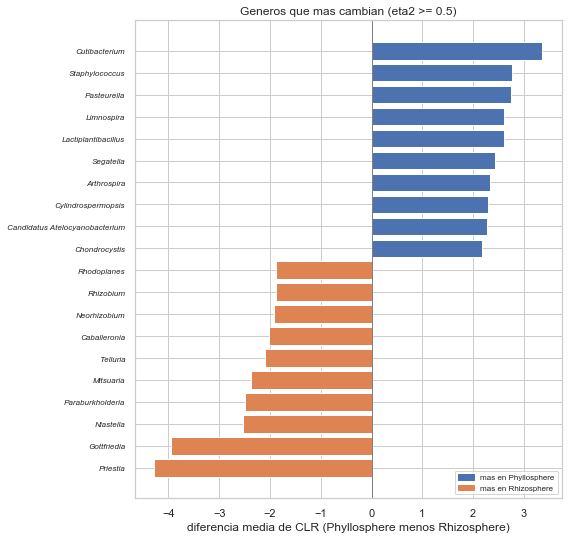

In [32]:
#| label: fig-l3-generos
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Géneros que más cambian entre filosfera y rizosfera, entre los que cambian de forma consistente (η² ≥ 0.5)."
figura = figura_generos(tabla, grupo_positivo="Phyllosphere", grupo_negativo="Rhizosphere")

**Mas en la raiz** (naranja): *Rhizobium*, *Neorhizobium*, *Paraburkholderia*,
*Caballeronia*, *Priestia*, *Gottfriedia*... Son bacterias tipicas de suelo y raiz:
fijadoras de nitrogeno, promotoras del crecimiento vegetal y formadoras de esporas (las dos
ultimas se llamaban antes *Bacillus*). Exactamente lo que uno esperaria.

**Mas en la hoja** (azul) hay tres tipos de generos, y conviene separarlos:

- **Cianobacterias** (*Limnospira*, *Arthrospira*, *Cylindrospermopsis*, *Chondrocystis*...):
  hacen fotosintesis, asi que tiene sentido encontrarlas en superficies al sol. Pero
  cuidado: los **cloroplastos** de la planta descienden de cianobacterias, y en la hoja
  casi todo el ADN es de la planta. Parte de estas lecturas podria ser ADN de cloroplasto
  mal asignado.
- ***Lactiplantibacillus***: bacterias lacticas, comunes en superficies vegetales y en
  fermentaciones como la del pulque.
- **Bacterias de piel y mucosas** (*Cutibacterium*, *Staphylococcus*, *Pasteurella*,
  *Segatella*): no esperariamos verlas en una penca. Las vemos abajo.

Busquemos algunos generos conocidos.

In [33]:
#| label: tbl-l3-conocidos
#| tbl-cap: "Géneros conocidos de hoja y de raíz: diferencia media de CLR (hoja menos raíz) y consistencia."
CONOCIDOS = ["Methylobacterium", "Methylorubrum", "Bradyrhizobium", "Rhizobium",
             "Mesorhizobium", "Streptomyces"]
tabla.loc[CONOCIDOS].round(2)

,diferencia,eta2
Methylobacterium,0.99,0.40
Methylorubrum,1.10,0.44
Bradyrhizobium,-1.49,0.79
Rhizobium,-1.88,0.66
Mesorhizobium,-1.12,0.79
Streptomyces,-0.72,0.49


- ***Methylobacterium*** y ***Methylorubrum*** salen **mas en la hoja**. Son el ejemplo
  clasico de bacteria de filosfera: se alimentan del metanol que liberan las hojas.
- ***Bradyrhizobium***, ***Rhizobium*** y ***Mesorhizobium*** (rizobios, fijadores de
  nitrogeno) y ***Streptomyces*** (actinobacteria de suelo) salen **mas en la raiz**.

Nadie le dijo al analisis que generos esperar, y aun asi los conocidos caen del lado
correcto. Eso es lo que da confianza en un resultado con datos reales: **que tenga sentido
biologico**, no solo un valor p pequeno.

Fijate tambien en que los metilotrofos tienen eta2 de 0.40-0.44: cambian, pero no en todas
las hojas. Con 7 hojas, es lo que se puede esperar.

### Una advertencia: los sospechosos de siempre

En la lista de la filosfera aparecen generos que no esperariamos en una hoja de agave.

In [34]:
#| label: tbl-l3-sospechosos
#| tbl-cap: "Géneros típicos de la piel humana en la comparación hoja contra raíz."
SOSPECHOSOS = ["Cutibacterium", "Staphylococcus"]
tabla.loc[SOSPECHOSOS].round(2)

,diferencia,eta2
Cutibacterium,3.36,0.58
Staphylococcus,2.78,0.66


*Cutibacterium* y *Staphylococcus* son las bacterias mas comunes de la **piel humana**, y
aqui son de los generos que mas suben en la hoja.

La explicacion mas probable no es biologica sino tecnica. Recordemos la revision 2: en la
hoja hay muy poco ADN bacteriano. Cuando hay poca biomasa, cualquier contaminacion
(de quien tomo la muestra, de los reactivos del laboratorio) pesa mucho mas en la
proporcion. Es un problema conocido de las muestras de **baja biomasa**.

> La leccion: que un genero salga arriba en la lista no lo convierte en hallazgo.
> Primero hay que preguntarse si tiene sentido biologico.

## 8. ¿Y un clasificador?

En la 10 terminamos clasificando. Aqui no, a proposito: con 15 muestras, cada pliegue de
validacion cruzada tendria dos o tres muestras de prueba, y el porcentaje de aciertos
saltaria muchisimo de una particion a otra. Con tan pocas muestras, la PERMANOVA es la
herramienta adecuada: usa todas las muestras a la vez y nos da un valor p.

## 9. Resumen

| pregunta | respuesta |
|---|---|
| ¿Se separan raiz y hoja en el ACP? | sin CLR no; con CLR si (eta² de PC1: 0.20 → 0.60) |
| ¿Es real la diferencia? | si: R² = 0.31, p = 0.001 |
| ¿Depende del estudio? | no parece: dentro de un solo estudio, R² = 0.35 |
| ¿Depende del umbral o de la muestra rara? | cambia el tamano (R² 0.15 a 0.41), no la conclusion |
| ¿Tiene sentido biologico? | si: metilotrofos en hoja; rizobios y bacterias de suelo en raiz |
| ¿Hay que desconfiar de algo? | de la piel humana en la hoja (baja biomasa) y de las cianobacterias (cloroplastos) |

## Lo que se llevan para su subset

Antes de cualquier ACP o clasificador, respondan con su subset:

1. **¿Hay muestras repetidas?** Usen `perfiles_duplicados`.
2. **¿Sus grupos se secuenciaron igual?** Comparen lecturas y fraccion sin clasificar.
3. **¿Que reinos hay en la tabla?** Decidan con que se quedan y por que.
4. **¿De cuantos estudios viene cada grupo?** Si un grupo sale de un solo estudio, no
   podran distinguir grupo de laboratorio. La libreta 12 muestra que pasa entonces.
5. **¿El resultado aguanta?** Cambien el umbral y quiten las muestras raras.
6. **¿Tiene sentido biologico?** Busquen en la literatura los generos que salgan arriba.